# Stage 3, step 3: build BioLangFusion and examine the reproduction

This notebook connects cached sequence features to trained predictions. [Step 1](01_blf_datasets.ipynb) inspects the available benchmarks and the current count-matching filter; [step 2](02_token_embeddings.ipynb) extracts token features from three frozen encoders. Here we assemble the codon grid, three alternative fusion methods, and a TextCNN prediction head, then compare their performance with BioLangFusion.

The purpose is to establish a baseline that later encoder swaps and new fusion designs can be compared against. That requires both an understandable implementation and evidence about its behavior. Matching a published score alone would not establish that the datasets, preprocessing, architecture, or training procedure match. This work belongs to [Gantt and Details, task 17](../../docs/Research_Project_Plan_Gantt.xlsx); interpreting discrepancies before adding complexity belongs to task 19.

The reading path is **published reference → model and structural checks → experiment settings → training → results → controlled follow-up questions**. The pretrained encoders stay frozen. The DNA resampling, fusion layers, and prediction head contain parameters learned from labeled training examples.

**Current evidence.** Saved outputs and nine result files document the October 17 fungal-expression experiment, using the appendix convolution setting, 100 TextCNN channels, and recorded seed 0. The alternative convolution and wider-head experiments have not produced saved results here. Outputs retained during this revision are historical observations, not fresh execution of the revised code. The original initialization and recovery behavior also differed from the repaired helpers described below.

---

## Setup

The imports prepare data handling, PyTorch, and the project's shared model code. The path block finds `Code/shared_code/`; it does not load benchmark CSVs, embedding caches, or pretrained models. Those inputs are opened later, after the comparison and assumptions are explained.

The model implementation is shared with later experiments rather than copied into this notebook:

| Module | Responsibility |
| --- | --- |
| [`codon_grid.py`](../shared_code/fusion/codon_grid.py) | Put the three token streams on a common position axis. |
| [`heads.py`](../shared_code/fusion/heads.py) | Concatenation, gated MIL, and cross-attention fusion. |
| [`textcnn.py`](../shared_code/fusion/textcnn.py) | Predict from a sequence of features. |
| [`blf.py`](../shared_code/fusion/blf.py) | Join dataset rows to caches, construct batches, and assemble models. |
| [`train.py`](../shared_code/fusion/train.py) | Optimization, validation-based selection, scoring, and result/checkpoint handling. |

The helpers' docstrings explain implementation choices. The small synthetic checks below and [`test_fusion_model.py`](../../tests/test_fusion_model.py) check software properties; they do not establish biological validity or a successful reproduction.

In [1]:
# Standard library
import os
import sys
import time
from dataclasses import asdict, replace
from pathlib import Path

# Configure the Apple backend before importing PyTorch; preserve an existing setting.
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import numpy as np
import pandas as pd
import torch
from IPython.display import display

In [2]:
# Locate Code/ from this notebook's working directory or its parents.
CODE_DIR = Path.cwd() / "Code"
for folder in (Path.cwd(), *Path.cwd().parents):
    if (folder / "shared_code").is_dir():
        CODE_DIR = folder
        break

if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

# These are the five Python modules listed in the setup table above.
from shared_code.fusion import blf, codon_grid, heads, textcnn, train

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

torch 2.10.0+cu126 | Apple GPU available: False


### Device and execution controls

The notebook selects an available PyTorch backend: Apple MPS, then NVIDIA CUDA, then CPU. The MPS fallback setting above lets unsupported Apple GPU operations use the CPU; it does not select a device or enable CUDA. CUDA availability depends on the installed PyTorch build and driver. The selected device is used only when an experiment is enabled; the structural demonstrations use small CPU tensors.

All five switches below start at `False`. With these defaults, the notebook reads saved results and performs the small structural demonstrations without opening research caches, timing optimization, or fitting models. To run an operation, change its switch, rerun Setup and the configuration/cache cells, then run that section. The switches control this notebook's calls; they do not erase saved outputs or alter the shared trainer.

Saved outputs belong to their producing executions, even when the switches are now off. Keep them as evidence rather than treating a displayed timing or score as a new measurement. The result sections print the selected comparison directory; execution provenance belongs in the [run records](../../docs/run-records.md).

In [ ]:
# Opt in separately: even timing and the short probe perform optimization.
RUN_TIMING = False
RUN_PROBE = False
RUN_MAIN_SWEEP = False
RUN_EQUATION_SWEEP = False
RUN_WIDE_HEAD = False

# Preserve the existing automatic preference; make Windows CUDA support visible here.
mps_available = torch.backends.mps.is_available()
cuda_available = torch.cuda.is_available()
if mps_available:
    DEVICE = "mps"
elif cuda_available:
    DEVICE = "cuda"
else:
    DEVICE = "cpu"

print("PyTorch:", torch.__version__)
print("CUDA available:", cuda_available, "| Apple MPS available:", mps_available)
print("Selected device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name())
print("Enabled operations:", {
    "timing": RUN_TIMING, "probe": RUN_PROBE, "main sweep": RUN_MAIN_SWEEP,
    "equation sweep": RUN_EQUATION_SWEEP, "wide head": RUN_WIDE_HEAD,
})

---

## The published comparison

[BioLangFusion, Table 1](../../Papers/core/BioLangFusion.pdf) reports seven individual encoders and three fusion methods across five benchmarks. We retain the full reference table, but the training sweep below runs the three encoders actually used for fusion: NT v2 100M, RNA-FM, and ESM-2 8M. The other four encoders are context, not locally reproduced runs in this notebook.

`TABLE4` contains two selected gated-MIL ablations plus their reference row. It is not the complete paper table. In particular, the token-level attention and no-codon-grid concatenation comparisons are outside this sweep. The shared-projection option exists in `heads.py`, but is also not included in the nine saved runs.

Regression uses **Spearman correlation**, which compares prediction and target rankings. E. coli uses **accuracy in percent** in these reference tables. Training results store accuracy as a fraction; the comparison code converts it to the paper's scale. Differences in these units should not be averaged together.

In [3]:
# BioLangFusion Table 1 in full, as printed. Spearman correlation everywhere except E. coli,
# which is accuracy on a 0 to 100 scale. The first four rows are encoders the paper compares
# against but does not fuse; rows five to seven are the three it fuses.
TABLE1 = pd.DataFrame(
    [
        ("Evo",                     "other",    0.653, 0.579, 42.556, 0.403, 0.360),
        ("SpliceBERT",              "other",    0.802, 0.778, 48.455, 0.522, 0.718),
        ("ESM-2 (650M)",            "other",    0.825, 0.734, 46.348, 0.536, 0.679),
        ("ESM-2 (3B)",              "other",    0.772, 0.721, 46.208, 0.537, 0.700),
        ("ESM-2 (8M)",              "single",   0.806, 0.695, 49.017, 0.539, 0.711),
        ("RNA-FM",                  "single",   0.841, 0.767, 52.949, 0.553, 0.743),
        ("Nucleotide Transformer",  "single",   0.780, 0.804, 41.292, 0.530, 0.732),
        ("Concatenation",           "fusion",   0.831, 0.805, 50.280, 0.539, 0.764),
        ("MIL + Entropy",           "fusion",   0.864, 0.824, 52.107, 0.563, 0.760),
        ("Cross Attention",         "fusion",   0.828, 0.812, 53.932, 0.550, 0.765),
    ],
    columns=["encoding", "kind", "cov_vac_degradation", "fungal_expression",
             "ecoli_proteins", "mrna_stability", "ab1"],
).set_index("encoding")

# Selected Table 4 rows: two gated-head ablations and their reference.
TABLE4 = pd.DataFrame(
    [
        ("MIL without entropy",                     0.854, 0.826, 51.960, 0.556, 0.753),
        ("MIL with shared projection (+ entropy)",  0.859, 0.813, 50.140, 0.563, 0.755),
        ("MIL + entropy",                           0.864, 0.824, 52.107, 0.563, 0.760),
    ],
    columns=["ablation", "cov_vac_degradation", "fungal_expression",
             "ecoli_proteins", "mrna_stability", "ab1"],
).set_index("ablation")

display(TABLE1)
display(TABLE4)

,kind,cov_vac_degradation,fungal_expression,ecoli_proteins,mrna_stability,ab1
encoding,,,,,,
Evo,other,0.653,0.579,42.556,0.403,0.360
SpliceBERT,other,0.802,0.778,48.455,0.522,0.718
ESM-2 (650M),other,0.825,0.734,46.348,0.536,0.679
ESM-2 (3B),other,0.772,0.721,46.208,0.537,0.700
ESM-2 (8M),single,0.806,0.695,49.017,0.539,0.711
RNA-FM,single,0.841,0.767,52.949,0.553,0.743
Nucleotide Transformer,single,0.780,0.804,41.292,0.530,0.732
Concatenation,fusion,0.831,0.805,50.280,0.539,0.764
MIL + Entropy,fusion,0.864,0.824,52.107,0.563,0.760


,cov_vac_degradation,fungal_expression,ecoli_proteins,mrna_stability,ab1
ablation,,,,,
MIL without entropy,0.854,0.826,51.960,0.556,0.753
MIL with shared projection (+ entropy),0.859,0.813,50.140,0.563,0.755
MIL + entropy,0.864,0.824,52.107,0.563,0.760


**What would a fusion gain mean?** Compare each fusion method with the strongest of the three constituent encoders under the same evaluation conditions:

$$
\Delta_{\mathrm{fusion}} = s_{\mathrm{fusion}} - \max(s_{\mathrm{DNA}}, s_{\mathrm{RNA}}, s_{\mathrm{protein}}).
$$

Here $s$ is the task's evaluation score, and $\Delta_{\mathrm{fusion}}$ is the difference in that score's units. For the published fungal results, concatenation gains $0.805 - 0.804 = 0.001$, while gated MIL gains $0.824 - 0.804 = 0.020$. The small size of these differences makes variation between runs important. Similar absolute scores and a matching rank order answer different descriptive questions; neither alone proves reproducibility.

**The paper's gains depend on the task and method.** Its Table 1 does not show every fusion method beating the strongest single encoder everywhere. Among the three main fusion methods, MIL leads on three benchmarks and cross-attention on E. coli and Ab1. We should compare these task-specific patterns rather than require every fusion method to win.

**Entropy is not uniformly beneficial in Table 4.** Removing entropy gives fungal expression 0.826 versus 0.824 with it. On stability, the corresponding values are 0.556 and 0.563: they are not tied. Entropy improves four of the five listed point estimates and lowers fungal expression's. These are comparisons of reported point estimates, not uncertainty estimates. The saved sweep includes both positive-lambda MIL and the lambda-zero ablation so that this contrast remains visible.

### Why begin with fungal expression?

Fungal expression is a manageable first build check: the current filter retains 3,138 rows, the task is regression, and the paper reports the three constituent encoders and all three fusion methods. Step 1 found no exact sequence crossing its published split boundaries. That does not establish independence between related sequences, identical author preprocessing, or correctness of the model merely because scores are close.

The other benchmarks answer additional questions:

- **mRNA stability:** 2,444 of 3,579 saved test rows share a sequence with training, about 68.3%. A published-split run is still useful for comparability, but it cannot be described as evaluation exclusively on unseen sequences. A separately defined sequence-grouped evaluation asks a different question. Differing labels for repeated sequences do not reveal the cause of the overlap or how much performance comes from memorization.
- **CoV-Vac:** the 81-nucleotide inputs make the first-base translation and stop-to-`X` policy especially consequential. Source coordinates and biological reading frame remain unresolved. It is inexpensive to test, but agreement would reflect this implementation choice as well as the model.
- **E. coli:** classification exercises the task-specific loss, output dimensions, and accuracy calculation.
- **Ab1:** the fifth benchmark is not available in the current registry. Its original data and preprocessing must be obtained and verified before claiming five-benchmark coverage.

The original notebook suggested CoV-Vac and E. coli as subsequent build checks. Their order remains a planning choice; the current experiment is fungal expression only. Earlier detailed stability counts and the fragment-translation percentages are retained in the final historical-context note, with their evidence limits.

---

## How the model uses the cached features

Each benchmark row starts from one supplied nucleotide sequence and a target `Value`. Step 2 derives DNA and RNA views by alphabet conversion and a protein view by translating complete triplets from the chosen origin, with stops represented as `X`. These are three representations of the same row, not three independently measured biological assays. Different pretrained encoders may expose complementary features, but that benefit must be tested against the single-encoder baselines.

Each cached row supplies three matrices: token positions by hidden features. Their widths are **512 for DNA, 640 for RNA, and 320 for protein**. The position counts differ because the tokenizers represent different units. The codon grid makes a shared position axis; the chosen fusion method combines features on that axis; TextCNN learns to predict the target from the resulting sequence.

| Component | Operation | What to keep in mind |
| --- | --- | --- |
| Codon grid | Average RNA triplets; upsample DNA features; use protein positions as the reference. | Matching array lengths does not establish the input's biological reading frame. |
| Concatenation | Project DNA, join the three feature vectors at each position, then project the joined vector. | The default DNA projection is 512 to 600 features, so it expands rather than compresses the actual hidden states. |
| Gated MIL | Summarize each modality over real positions and learn one weight per modality per sequence. | Its weights describe learned allocation, not a causal attribution to biological mechanisms. |
| Cross-attention | Let each modality attend to a joint context containing all three streams. | It also receives the codon-grid outputs and may be affected by changes to that grid. |
| TextCNN | Apply width-3, -4, and -5 convolutions, ReLU, masked max pooling, dropout, and a final prediction layer. | The shared architecture is trainable; “fixed” does not mean frozen weights. |

The three unimodal baselines use TextCNN directly on one stream at its native resolution. A convolution therefore spans different sequence units in those baselines. This is the implemented comparison design, not proof that every interpretation of “matched head” is equivalent.

With `CHANNELS=100`, TextCNN learns 100 filters for **each** kernel width (3, 4, and 5). Masked max pooling keeps one activation per filter, so the three branches supply 300 features to dropout and the final prediction layer. For fungal regression, that layer returns one number per row. Each run trains its own weights; sharing a head architecture does not mean sharing a fitted head across variants.

**Follow one row.** For an illustrative 120-nucleotide sequence containing only canonical bases, special tokens removed, the caches contain $20\times512$ DNA, $120\times640$ RNA, and $40\times320$ protein features. The first dimension counts positions; the second is the vector width at each position. The diagram shows the current appendix setting and a separate unimodal comparison route.

![A 120-nucleotide example passes from frozen cached DNA, RNA and protein features through a 40-position grid, one trainable fusion method and its own TextCNN to one prediction. Unimodal models bypass the grid and fusion and train their own TextCNN on one native stream.](attachment:blf-architecture.svg)

The appendix DNA convolution produces 37 positions and pads to 40 in this example; RNA triplet averaging and protein passthrough need no learned parameters. The selected fusion returns $40\times600$ features before TextCNN. These shapes illustrate the implemented data flow, not verified biological correspondence or a newly executed example. See `CodonGrid`, the three fusion classes, and `TextCNN` in the linked modules above.
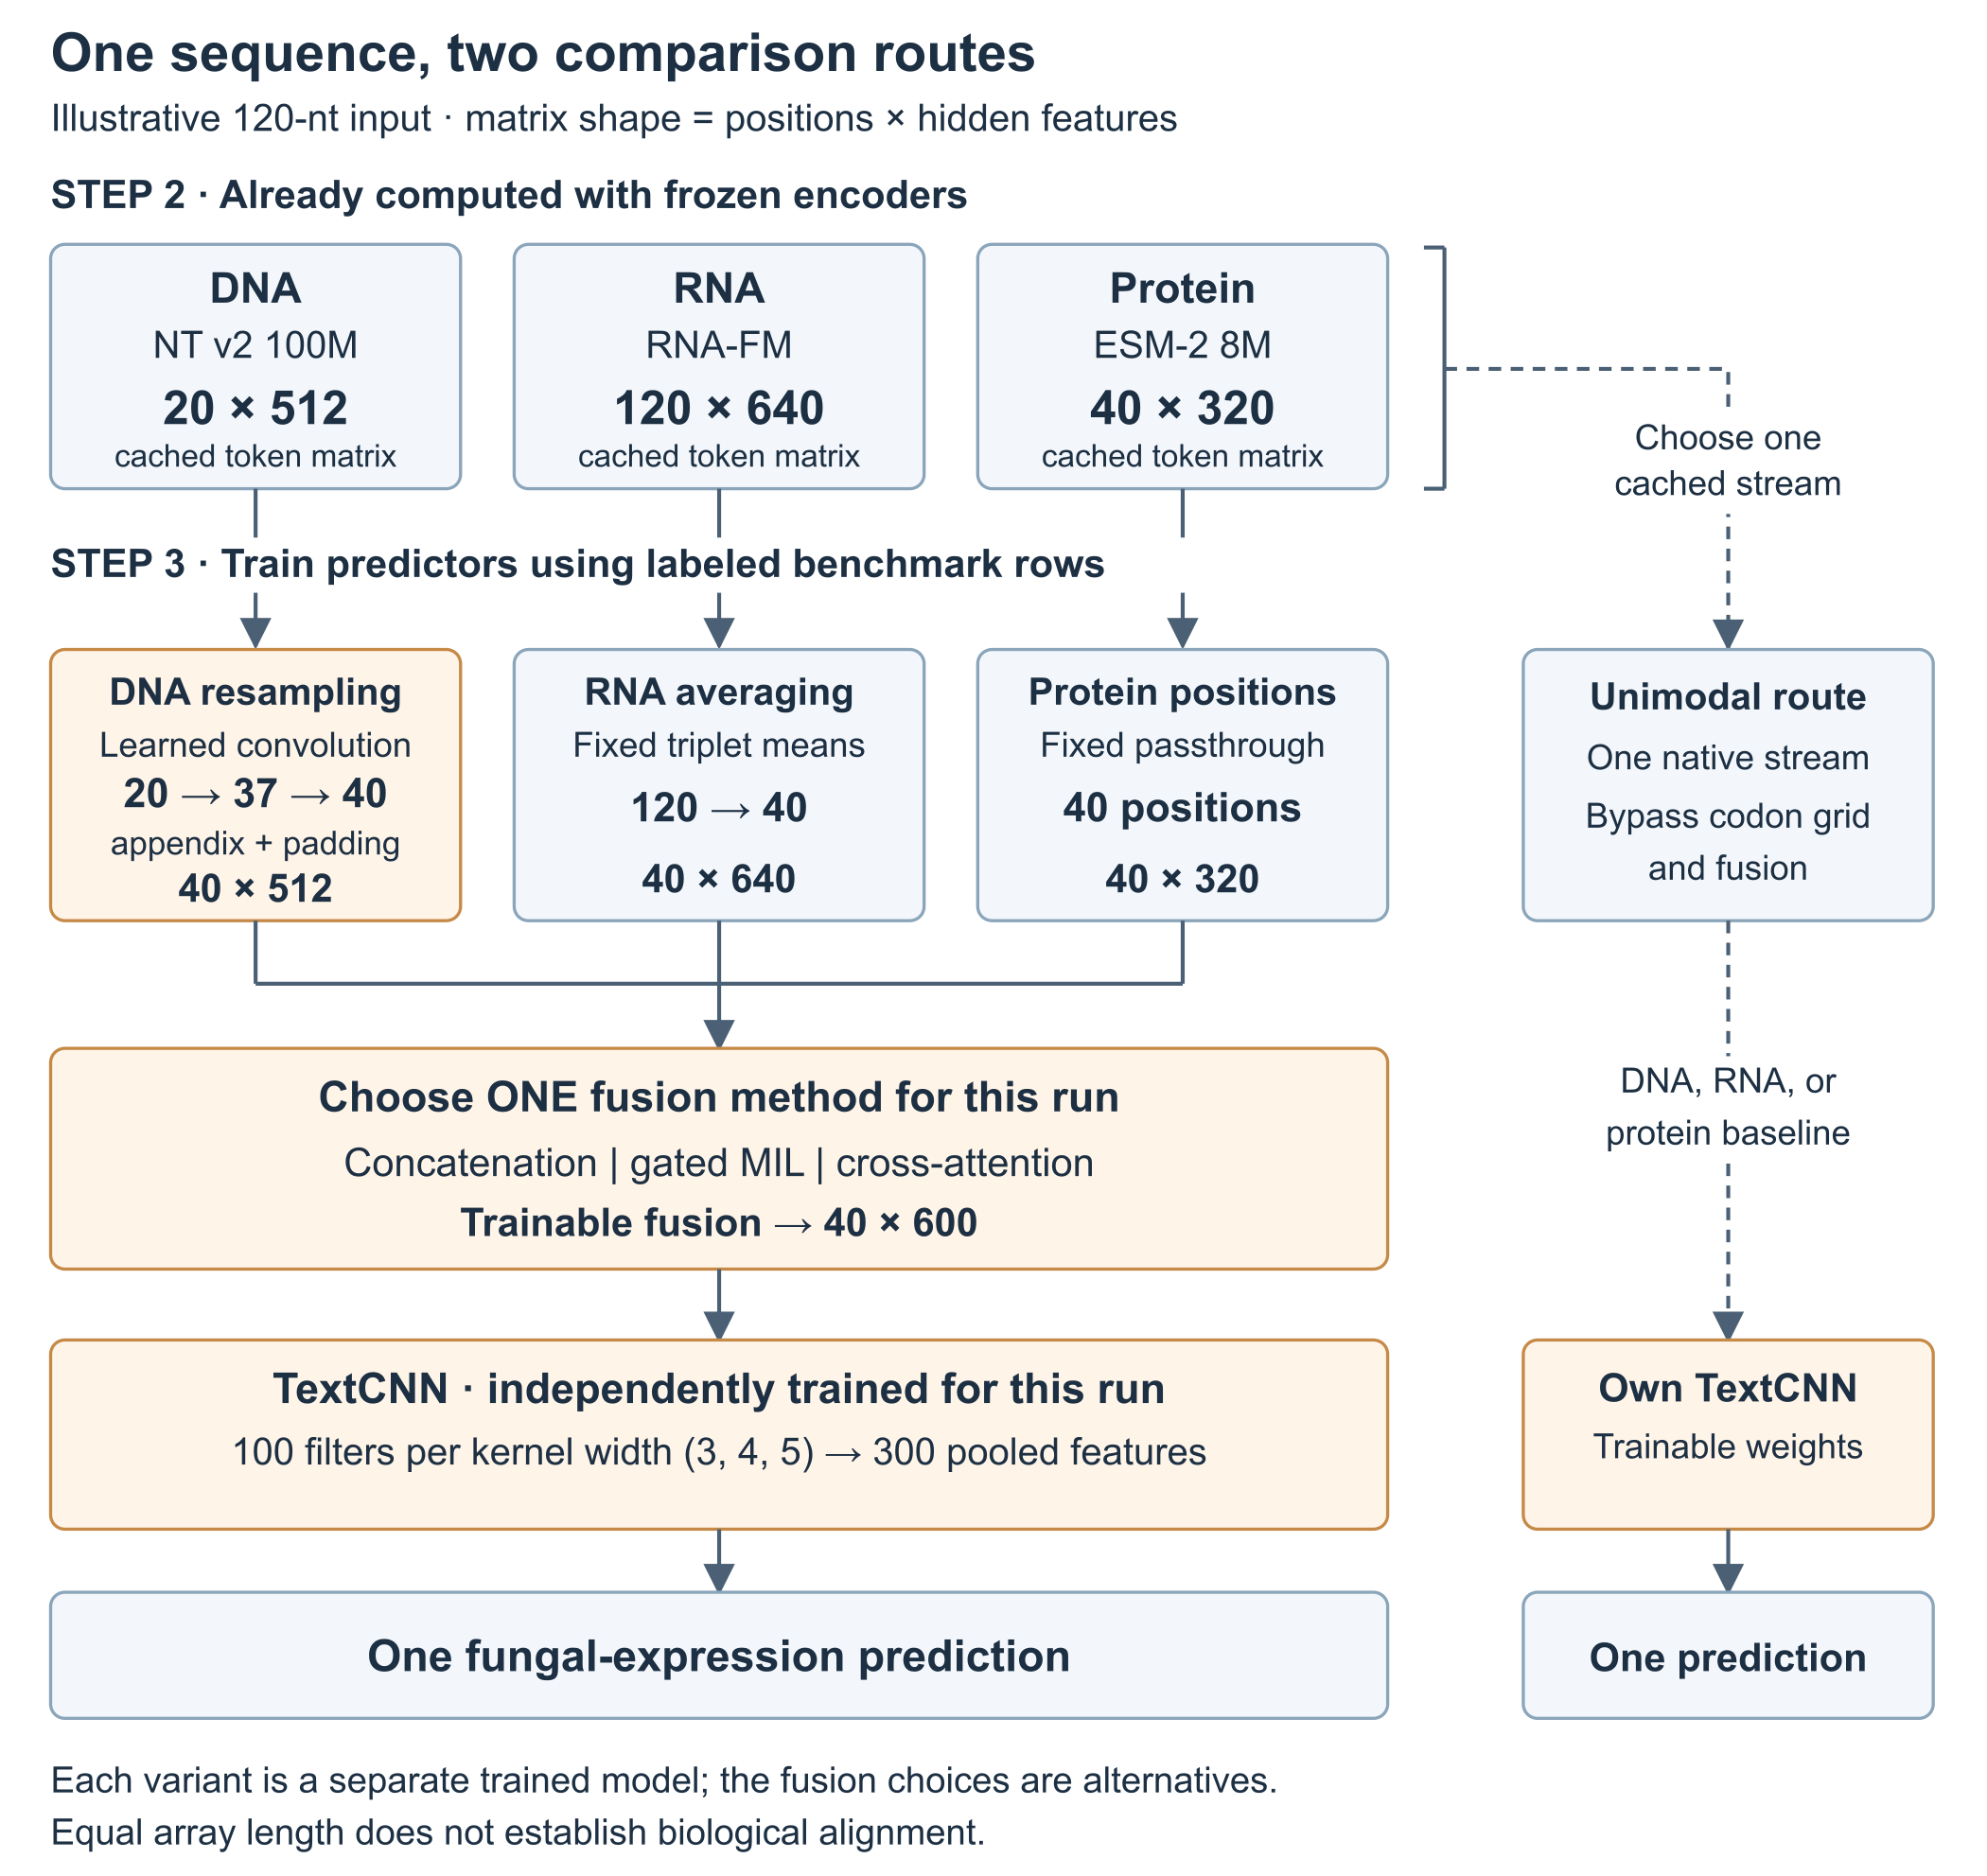

### What the paper leaves open

The implementation makes the following choices explicit rather than treating them as uniquely determined by the paper:

| Question | Current choice and reason for checking it |
| --- | --- |
| DNA resampling | Equation 1 gives kernel 2, stride 2; Appendix Lists 1–2 give kernel 3, stride 2, padding 2. Both are available. The saved experiment used the appendix setting; its performance consequences are still a hypothesis. |
| TextCNN width | List 1 gives 1,280 channels for MIL and List 2 gives 100 for cross-attention. The main comparison uses 100 for all methods. A common width controls one architectural choice, but 100 is not the only possible common width. |
| DNA width and projection | The paper lists 4,107, which is the checkpoint's vocabulary size; the hidden-state width is 512. DNA is intermediate between RNA and protein, not the narrowest. The 600-feature projection is retained as an explicit implementation choice. |
| Early stopping and scheduling | Both monitor validation score. The best validation epoch is restored before final test scoring. The paper does not fully specify these monitors. |
| Padding and averaging | Means and prediction pooling exclude padded positions. DNA outputs are limited to each row's own convolution length before masking. Otherwise batch composition can change a row's representation. |

**Why the mask matters.** A short row is padded to the longest row in its batch. For one illustrative feature, real values `[2, 4]` average to 3; averaging `[2, 4, 0, 0]` after padding would give 1.5. A longer batch mate should not change that summary. The mask excludes the padding. The grid and TextCNN checks below test related padding invariances.

For a sequence with $T$ nucleotides, the current protein input has $\lfloor T/3 \rfloor$ positions. The audited retained sequences have lengths divisible by three, but that arithmetic does not establish a coding annotation. RNA's triplet averaging follows the same first-base convention; DNA's actual tokenizer positions require separate treatment, discussed in the convolution investigation.

### Structural checks before opening research caches

These checks use invented tensors on the CPU. They ask whether the implemented shapes, masking, and gradients behave as intended. They do not test published score agreement, biological correspondence, or the identity of an embedding cache.

The checks are grouped into position handling, prediction/gate behavior, and gradient flow. A seed makes these particular test inputs repeatable; training initialization has its own per-run seed. A failed check should be investigated before an expensive experiment.

In [4]:
# Synthetic checks: no research cache, encoder checkpoint, or model training.
torch.manual_seed(0)
feature_widths = {"dna": 512, "rna": 640, "prot": 320}
structural_checks = []


def record_check(name, passed, detail):
    """Keep one interpretable row for each independent structural check."""
    structural_checks.append({
        "check": name,
        "result": "ok" if passed else "PROBLEM",
        "detail": detail,
    })


# Both settings must return the requested frame, including NT remainder tokens.
for setting in codon_grid.TCONV_SETTINGS:
    grid = codon_grid.CodonGrid(feature_widths["dna"], tconv=setting).eval()
    nucleotide_count = 999
    dna_token_count = nucleotide_count // 6 + nucleotide_count % 6
    dna = torch.randn(2, dna_token_count, feature_widths["dna"])
    rna = torch.randn(2, nucleotide_count, feature_widths["rna"])
    protein = torch.randn(2, nucleotide_count // 3, feature_widths["prot"])
    codon_counts = torch.tensor([nucleotide_count // 3] * 2)
    dna_token_counts = torch.tensor([dna_token_count] * 2)
    with torch.no_grad():
        aligned_streams, position_mask = grid(dna, rna, protein, codon_counts, dna_token_counts)
    position_counts = {name: stream.shape[1] for name, stream in aligned_streams.items()}
    record_check(
        f"codon frame, tconv={setting}",
        set(position_counts.values()) == {nucleotide_count // 3},
        f"999 nt -> {position_counts}, expected {nucleotide_count // 3} everywhere",
    )

# Compare the same short sequence alone and beside a longer padded sequence.
grid = codon_grid.CodonGrid(feature_widths["dna"]).eval()
short_length, long_length = 300, 999
dna = torch.zeros(2, long_length // 6 + long_length % 6, feature_widths["dna"])
rna = torch.zeros(2, long_length, feature_widths["rna"])
protein = torch.zeros(2, long_length // 3, feature_widths["prot"])
for row, length in enumerate((short_length, long_length)):
    dna_count = length // 6 + length % 6
    dna[row, :dna_count] = torch.randn(dna_count, feature_widths["dna"])
    rna[row, :length] = torch.randn(length, feature_widths["rna"])
    protein[row, :length // 3] = torch.randn(length // 3, feature_widths["prot"])
codon_counts = torch.tensor([short_length // 3, long_length // 3])
dna_token_counts = torch.tensor([
    short_length // 6 + short_length % 6,
    long_length // 6 + long_length % 6,
])
with torch.no_grad():
    batched, _ = grid(dna, rna, protein, codon_counts, dna_token_counts)
    alone, _ = grid(
        dna[:1, :dna_token_counts[0]], rna[:1, :short_length],
        protein[:1, :short_length // 3], codon_counts[:1], dna_token_counts[:1],
    )
largest_difference = max(
    float((batched[name][:1, :short_length // 3] - alone[name]).abs().max())
    for name in alone
)
record_check("a row is unchanged by its batch mates", largest_difference == 0.0,
             f"largest difference {largest_difference:.3g}")

In [5]:
# Padded positions should not compete with real features in TextCNN's max pooling.
prediction_head = textcnn.TextCNN(feature_widths["rna"], 1, channels=16).eval()
real_features = torch.randn(1, 120, feature_widths["rna"])
padded_features = torch.cat([real_features, torch.randn(1, 60, feature_widths["rna"])], dim=1)
padded_mask = torch.zeros(1, 180, dtype=torch.bool)
padded_mask[:, :120] = True
with torch.no_grad():
    original_prediction = prediction_head(real_features, torch.ones(1, 120, dtype=torch.bool))
    padded_prediction = prediction_head(padded_features, padded_mask)
    prediction_difference = float((original_prediction - padded_prediction).abs().max())
record_check("the head ignores padding", prediction_difference < 1e-5,
             f"largest difference {prediction_difference:.3g}")

# Gated MIL assigns one normalized weight to each modality for each sequence.
aligned_streams, position_mask = grid(dna, rna, protein, codon_counts, dna_token_counts)
_, gate_details = heads.GatedMILFusion(feature_widths)(aligned_streams, position_mask)
modality_weights = gate_details["alpha"]
weights_are_valid = (
    modality_weights.shape == (2, 3)
    and bool(torch.allclose(modality_weights.sum(1), torch.ones(2)))
)
record_check(
    "gated attention: one weight per modality per sequence", weights_are_valid,
    f"shape {tuple(modality_weights.shape)}, row sums "
    f"{[round(float(value), 6) for value in modality_weights.detach().sum(1)]}",
)

In [6]:
# A synthetic backward pass checks connectivity and finite gradients, not learning quality.
for fusion_name, fusion_class in heads.FUSIONS.items():
    fusion_model = fusion_class(feature_widths)
    detached_streams = {name: values.detach() for name, values in aligned_streams.items()}
    fused_features, _ = fusion_model(detached_streams, position_mask)
    fused_features.sum().backward()
    invalid_gradients = [
        name for name, parameter in fusion_model.named_parameters()
        if parameter.requires_grad
        and (parameter.grad is None or not torch.isfinite(parameter.grad).all())
    ]
    record_check(
        f"gradients reach every parameter, {fusion_name}", not invalid_gradients,
        "all finite" if not invalid_gradients else f"missing: {invalid_gradients}",
    )

display(pd.DataFrame(structural_checks).set_index("check"))

,result,detail
check,,
"codon frame, tconv=appendix",ok,"999 nt -> {'dna': 333, 'rna': 333, 'prot': 333..."
"codon frame, tconv=equation",ok,"999 nt -> {'dna': 333, 'rna': 333, 'prot': 333..."
a row is unchanged by its batch mates,ok,largest difference 0
the head ignores padding,ok,largest difference 0
gated attention: one weight per modality per sequence,ok,"shape (2, 3), row sums [1.0, 1.0]"
"gradients reach every parameter, concat",ok,all finite
"gradients reach every parameter, mil",ok,all finite
"gradients reach every parameter, cross",ok,all finite


---

## Configure and run the experiment

The Setup switches decide which operations run; the settings below describe one comparison: a benchmark, a convolution setting, a TextCNN width, and a training seed. `BASE_CONFIG` also exposes the optimization defaults in `train.py`. `replace` changes only the named setting for an ablation; it does not modify the original configuration.

`CACHE_ROOT` identifies step 2's token files and is opened only when a diagnostic or training switch is enabled. Reading saved results needs no token files. A separate Git worktree may not contain these large ignored caches; inspect the printed path before enabling computation. No caches are copied, rebuilt, or redirected automatically.

`HISTORICAL_RESULTS_DIR` holds the original tracked results, while `RESULTS_DIR` is a separate location for runs made with the repaired initialization and recovery code. `COMPARISON_DIR` explicitly chooses which set the result sections read; it starts with the historical set. After a new sweep, select `RESULTS_DIR` there to examine the new evidence. All paths are anchored to this project's `Code/stage3/` directory, independent of the notebook's launch folder.

`ALLOW_LEGACY_CACHE` defaults to `False`: old caches without ordered-input evidence cannot silently become verified inputs. If such caches are deliberately reused, set it to `True` and retain the resulting unverified-input qualification. A checksum calculated now identifies current bytes; it cannot recover missing producer evidence or prove their original row correspondence.

New extraction manifests record effective input order and local extraction code, but they are not complete producer records: unpinned encoder revisions and the extraction environment remain unresolved. Do not interpret a matching manifest as proof that a resumed extraction used identical model weights and software.

In [7]:
BENCHMARK = "fungal_expression"
SEED = 0
CHANNELS = 100  # Filters per kernel width; Appendix List 2 uses this width.
BATCH_SIZE = 32  # BioLangFusion Appendix List 3.
MAX_EPOCHS = 500  # Appendix List 3; early stopping can end a run sooner.
MAIN_TCONV = "appendix"
LAMBDAS = (0.01, 0.5, 1.0)  # The paper's positive weights, selected on validation.
ALLOW_LEGACY_CACHE = False

STAGE3_DIR = CODE_DIR / "stage3"
CACHE_ROOT = STAGE3_DIR / "embeddings"
HISTORICAL_RESULTS_DIR = STAGE3_DIR / "results" / BENCHMARK
RESULTS_DIR = HISTORICAL_RESULTS_DIR / "reproducible"
COMPARISON_DIR = HISTORICAL_RESULTS_DIR

BASE_CONFIG = train.TrainConfig(
    batch_size=BATCH_SIZE,
    max_epochs=MAX_EPOCHS,
    channels=CHANNELS,
    tconv=MAIN_TCONV,
    seed=SEED,
)

# Finish the single-encoder baselines first; leave costly cross-attention until last.
# This order preserves useful completed comparisons if the sweep is interrupted.
# Lambda zero is Table 4's separate "MIL without entropy" ablation.
RUNS = [
    ("unimodal:prot", {}),
    ("unimodal:dna", {}),
    ("unimodal:rna", {}),
    ("concat", {}),
]
for entropy_weight in LAMBDAS:
    RUNS.append(("mil", {"entropy_lambda": entropy_weight}))
RUNS.extend([("mil", {"entropy_lambda": 0.0}), ("cross", {})])

In [10]:
# Release any readers from an earlier execution of this cell before changing modes.
if "STREAMS" in globals() and STREAMS is not None:
    STREAMS.close()
STREAMS = None

print("Token caches:", CACHE_ROOT)
print("Training results:", RESULTS_DIR)
print("Comparison results:", COMPARISON_DIR)

needs_streams = any((RUN_TIMING, RUN_PROBE, RUN_MAIN_SWEEP,
                     RUN_EQUATION_SWEEP, RUN_WIDE_HEAD))
if needs_streams:
    # Opening caches checks metadata and lengths; it does not load encoder models.
    STREAMS = blf.BenchmarkStreams.open(
        BENCHMARK, CACHE_ROOT, allow_legacy_cache=ALLOW_LEGACY_CACHE,
    )
    print(f"{BENCHMARK}: {len(STREAMS.rows):,} rows, {STREAMS.task}, "
          f"widths {STREAMS.widths}, device {DEVICE}")
    print("splits:", {name: len(STREAMS.split_rows(name)) for name in ("train", "val", "test")})
else:
    print("Research caches not opened: all diagnostic and training switches are off.")

run_labels = []
for variant, overrides in RUNS:
    label = variant
    if "entropy_lambda" in overrides:
        label += f" (lam {overrides['entropy_lambda']})"
    run_labels.append(label)
print(f"Planned main sweep ({len(RUNS)} runs):", ", ".join(run_labels))

fungal_expression: 3,138 rows, regression, widths {'dna': 512, 'rna': 640, 'prot': 320}, device cuda
splits: {'train': 2153, 'val': 555, 'test': 430}
9 runs: unimodal:prot, unimodal:dna, unimodal:rna, concat, mil (lam 0.01), mil (lam 0.5), mil (lam 1.0), mil (lam 0.0), cross


### Estimate the training cost

Timing is optional and off by default. It performs optimization on temporary models and stores its table only in notebook memory; it does not create a completed-run JSON or resumable checkpoint.

`BenchmarkStreams.open` joins the shared loader's rows with token caches. It checks row counts and RNA/protein token lengths, and the revised helper checks available input-identity metadata. These checks are distinct from biological alignment. Old saved outputs predate the stricter identity checks.

With `RUN_TIMING=True`, the timing cell builds each model once, performs an untimed forward/backward warm-up, then measures up to three training batches and projects an epoch:

$$
\text{minutes per epoch} = \frac{\text{measured seconds}}{\text{measured batches}}\,\frac{\text{training batches per epoch}}{60}.
$$

This is an approximate cost estimate for these batches and this device. It omits validation, final scoring, result writes, and input hashing; GPU operations are not explicitly synchronized in this inherited timing method. Sequence lengths and device load can also change the cost. The 100- and 250-epoch columns are scenarios, not promises about convergence.

**Historical context retained.** Earlier four-CPU-thread estimates were 0.09 minutes per epoch for the short DNA/protein baselines, 0.52 for gated MIL, 0.53 for RNA-FM, 0.59 for concatenation, and 3.81 for cross-attention—about seven times the gated cost in that measurement. Cross-attention forms a context three times the codon-frame length, which helps explain its memory cost. An earlier 20-epoch DNA probe reached test Spearman 0.794 against 0.804 in the paper while validation was still rising. These observations do not determine the runtime or convergence of a new run, and that earlier test score should not guide further tuning.

The revised training helper also fingerprints the actual cache bytes before the first run on an opened stream set. Reading large caches can take appreciable time; the fingerprints are reused while those files remain unchanged. This checks present input identity, not historical producer provenance.

In [11]:
def time_variant(variant):
    """Estimate one variant's epoch cost, releasing its temporary model afterward."""
    if STREAMS is None:
        raise RuntimeError("Enable timing and rerun the cache-opening cell first.")
    training_batch_count = (len(STREAMS.split_rows("train")) + BATCH_SIZE - 1) // BATCH_SIZE
    model = None
    optimizer = None
    parameter_count = 0
    minutes_per_epoch = float("nan")
    failure_note = ""
    try:
        torch.manual_seed(SEED)
        model = blf.build(STREAMS, variant, channels=CHANNELS, tconv=MAIN_TCONV).to(DEVICE)
        parameter_count = sum(parameter.numel() for parameter in model.parameters())
        optimizer = torch.optim.Adam(model.parameters(), lr=BASE_CONFIG.lr)
        criterion = train.loss_function(STREAMS.task)
        batches = iter(blf.loader(STREAMS, "train", batch_size=BATCH_SIZE, shuffle=False))

        # Warm up the forward/backward path before measuring optimization batches.
        warmup = next(batches).to(DEVICE)
        output, _ = model(warmup)
        target = warmup.labels
        if STREAMS.task != "classification":
            target = target.view(-1, 1).float()
        criterion(output, target).backward()

        started = time.perf_counter()
        measured_batches = 0
        for batch in batches:
            batch = batch.to(DEVICE)
            optimizer.zero_grad()
            output, _ = model(batch)
            target = batch.labels
            if STREAMS.task != "classification":
                target = target.view(-1, 1).float()
            criterion(output, target).backward()
            optimizer.step()
            measured_batches += 1
            if measured_batches == 3:
                break

        if measured_batches == 0:
            failure_note = "No batches remained after warm-up."
        else:
            elapsed_seconds = time.perf_counter() - started
            minutes_per_epoch = elapsed_seconds / measured_batches * training_batch_count / 60
    except (RuntimeError, MemoryError, StopIteration) as problem:
        failure_note = f"{type(problem).__name__}: {str(problem)[:90]}"
    finally:
        del model, optimizer
        if DEVICE == "mps":
            torch.mps.empty_cache()
        elif DEVICE == "cuda":
            torch.cuda.empty_cache()

    return {"params": parameter_count, "min/epoch": round(minutes_per_epoch, 2),
            "note": failure_note}

In [12]:
timing = None
timing_rows = []
variants_to_time = []
sweep_minutes_per_epoch = None

if RUN_TIMING:
    if STREAMS is None:
        raise RuntimeError("Enable the operation in Setup, then rerun the cache-opening cell.")
    # Lambda changes reuse the same architecture, so time each variant only once.
    variants_to_time = []
    for variant, _ in RUNS:
        if variant not in variants_to_time:
            variants_to_time.append(variant)

    timing_rows = []
    for variant in variants_to_time:
        timing_rows.append({"variant": variant, **time_variant(variant)})
    timing = pd.DataFrame(timing_rows).set_index("variant")
    timing["hours @100"] = (timing["min/epoch"] * 100 / 60).round(1)
    timing["hours @250"] = (timing["min/epoch"] * 250 / 60).round(1)
    display(timing)

    if timing["min/epoch"].notna().all():
        runs_per_variant = pd.Series([variant for variant, _ in RUNS]).value_counts()
        sweep_minutes_per_epoch = (timing["min/epoch"] * timing.index.map(runs_per_variant)).sum()
        print(f"whole sweep, {len(RUNS)} runs: {sweep_minutes_per_epoch * 100 / 60:.1f} hours "
              f"at 100 epochs each, {sweep_minutes_per_epoch * 250 / 60:.1f} hours at 250")
    else:
        print("Whole-sweep projection unavailable: at least one variant was not measured.")
    for variant, failure_note in timing.loc[timing["note"] != "", "note"].items():
        print(f"NOT MEASURED  {variant}: {failure_note}")
else:
    print("Timing skipped (RUN_TIMING=False); saved timings are not new measurements.")

,params,min/epoch,note,hours @100,hours @250
variant,,,,,
unimodal:prot,384601,0.32,,0.5,1.3
unimodal:dna,615001,0.08,,0.1,0.3
unimodal:rna,768601,0.08,,0.1,0.3
concat,2751945,0.08,,0.1,0.3
mil,2753246,0.11,,0.2,0.5
cross,7805145,0.39,,0.6,1.6


whole sweep, 9 runs: 2.3 hours at 100 epochs each, 5.8 hours at 250


A finite timing entry means this small workload ran on the selected device. It is not a full memory or training check. Cross-attention may exceed memory at batch size 32; using a smaller batch is a deliberate configuration change that must be recorded and compared appropriately. A missing timing now prevents a misleading whole-sweep total that silently omits a failed model.

### What training learns and validation selects

The cached encoders stay frozen. Training adjusts the downstream model so that its predictions approach the labeled targets. For fungal expression, [`train.fit`](../shared_code/fusion/train.py) minimizes mean squared error (MSE), the batch average of $(\hat y_i-y_i)^2$. Validation and testing use **Spearman correlation** to assess ranking agreement instead. Lower training loss and higher validation correlation are different signals; neither must improve on every epoch.

For gated MIL, the implementation also penalizes the entropy of each example's three modality weights, following [BioLangFusion's gated-fusion objective, Section 2.2.2](../../Papers/core/BioLangFusion.pdf):

$$
H(\boldsymbol\alpha_i)=-\sum_{m=1}^{3}\alpha_{im}\ln\alpha_{im}.
$$

**In this notation:**

- $i$ identifies one example; $y_i$ is its target and $\hat y_i$ its prediction.
- $m$ identifies DNA, RNA, or protein. The nonnegative weights $\alpha_{im}$ sum to one for each example and are reused across that example's positions.
- $H$ measures how spread out those three weights are; $\ln$ is the natural logarithm.

Uniform weights $(1/3,1/3,1/3)$ have entropy $\ln 3$; concentrating nearly all weight on one modality makes entropy approach zero. The minimized batch objective is

$$
\mathcal L_{\mathrm{batch}}=\mathcal L_{\mathrm{MSE}}+\lambda\,\frac{1}{B}\sum_{i=1}^{B}H(\boldsymbol\alpha_i),
$$

where $B$ is the batch size and $\lambda$ controls the entropy penalty. A positive coefficient favors **concentrated**, not evenly balanced, weights. Lambda zero removes this penalty. The code clamps weights below $10^{-12}$ for numerical stability; Adam's separate weight-decay setting is not part of the displayed loss. Recorded `train_loss` averages these batch objectives over the epoch, weighted by their example counts, so losses from different lambdas are not directly comparable as MSE.

**Selection has two levels.** Within each run, validation Spearman chooses the epoch whose weights are restored. Across positive MIL candidates, validation chooses lambda from `{0.01, 0.5, 1}`; lambda zero remains a separate ablation. The test split reports performance after those within-run weights are restored. `fit` computes a test score for every fitted run, including the short probe and each lambda candidate, but the selection code uses validation scores only.

### A short training probe

With `RUN_PROBE=True`, the next cell trains the small protein-only predictor for five epochs and displays its loss and validation trajectory. A falling loss or rising validation score is useful diagnostic evidence, not a requirement that every short stochastic run must satisfy. `fit` also computes a final test score, but this probe does not use that score for decisions. Its result stays in memory; it does not create a saved sweep result.

The caller seeds **before** constructing the probe model. This is distinct from seeding the subsequent training operations: a seed set after construction cannot determine the already initialized weights. The saved curve below belongs to the earlier implementation.

In [13]:
probe = None
probe_curve = None

if RUN_PROBE:
    if STREAMS is None:
        raise RuntimeError("Enable the operation in Setup, then rerun the cache-opening cell.")
    probe_config = replace(BASE_CONFIG, max_epochs=5, early_stopping_patience=5)
    torch.manual_seed(probe_config.seed)
    probe_model = blf.build(STREAMS, "unimodal:prot", channels=CHANNELS)
    try:
        probe = train.fit(probe_model, STREAMS, probe_config, DEVICE, log=None)
    finally:
        del probe_model

    probe_curve = pd.DataFrame(probe.history)[["epoch", "train_loss", "val_score"]]
    probe_curve["val_score"] = pd.to_numeric(probe_curve["val_score"], errors="coerce")
    display(probe_curve)
    loss_fell = probe_curve["train_loss"].iloc[-1] < probe_curve["train_loss"].iloc[0]
    validation_rose = probe_curve["val_score"].iloc[-1] > probe_curve["val_score"].iloc[0]
    print(f"train loss falling: {loss_fell} | validation score rising: {validation_rose} | "
          f"{probe.seconds / probe_config.max_epochs:.1f} s per epoch")
else:
    print("Short probe skipped (RUN_PROBE=False); no model was fitted.")

,epoch,train_loss,val_score
0,0,6.178789,0.300158
1,1,5.200016,0.355518
2,2,4.999578,0.394792
3,3,4.777505,0.422065
4,4,4.613091,0.443542


train loss falling: True | validation score rising: True | 11.4 s per epoch


### Train the comparison sweep

With `RUN_MAIN_SWEEP=True`, this cell requests the comparison runs. A matching completed result is reused; a missing result is fitted or resumed from a compatible checkpoint. An incompatible existing result stops the request without overwriting it. The nine-run design contains three unimodal baselines, concatenation, three positive entropy weights for MIL, MIL without entropy, and cross-attention. Positive MIL weights are selected on validation performance; lambda zero remains a separate ablation.

`train.run` seeds before model construction, checks the complete recorded configuration and available input/code identity, and saves one result per completed run. During training, checkpoints are saved periodically (every ten epochs by default, including the first completed epoch), with a final checkpoint at completion. An interrupted run can resume only from a compatible saved checkpoint; work since that checkpoint may repeat rather than resuming at the exact interrupted batch. The revised checkpoint includes scheduler and random-generator state as well as model and optimizer state. Exact numerical continuation still depends on the environment and deterministic operations; its synthetic regression test is distinct from a research run.

Reading a saved result for analysis is different from accepting it as an identical computation. Source fingerprints can differ after a code merge even when the preserved result is still useful evidence. Missing per-row predictions cannot be recovered from a summary score, and do not trigger automatic retraining. An old or incompatible result is not deleted or silently reused. Keep it as historical evidence and choose an appropriate new result directory. Do not change cache files while `STREAMS` is open; close and reopen the streams if their inputs change. The saved October 17 sweep predates these repairs.

For a long **Mac** session, prevent sleep while the notebook kernel is running with this terminal command:

```sh
caffeinate -i -w $(pgrep -n -f ipykernel)
```

The run records describe an approximately one-hour original fungal sweep. That is an observation from its producing machine, not a forecast for this configuration or host.

In [14]:
elapsed_hours = None

if RUN_MAIN_SWEEP:
    if STREAMS is None:
        raise RuntimeError("Enable the operation in Setup, then rerun the cache-opening cell.")
    started = time.perf_counter()
    for variant, overrides in RUNS:
        run_config = replace(BASE_CONFIG, **overrides)
        train.run(STREAMS, variant, run_config, DEVICE, RESULTS_DIR)
    elapsed_hours = (time.perf_counter() - started) / 3600
    print(f"\nsweep finished in {elapsed_hours:.2f} hours")
    print("Results saved in:", RESULTS_DIR)
    print("To inspect this sweep below, set COMPARISON_DIR = RESULTS_DIR in the settings cell.")
else:
    print("Main sweep skipped (RUN_MAIN_SWEEP=False); saved results are read below.")

  fungal_expression__unimodal-prot__lambda0.0__ch100__appendix__seed0: training
    epoch   0  train loss 6.1788  val 0.3002  best 0.3002 @ 0
    epoch  10  train loss 3.9780  val 0.5481  best 0.5481 @ 10
    epoch  20  train loss 3.3710  val 0.6099  best 0.6099 @ 20
    epoch  30  train loss 2.9371  val 0.6353  best 0.6353 @ 30
    epoch  40  train loss 2.5516  val 0.6489  best 0.6493 @ 38
    epoch  50  train loss 2.2373  val 0.6546  best 0.6546 @ 50
    epoch  60  train loss 1.9449  val 0.6597  best 0.6619 @ 56
    epoch  70  train loss 1.8603  val 0.6613  best 0.6619 @ 56
  fungal_expression__unimodal-prot__lambda0.0__ch100__appendix__seed0: test 0.6975 (val 0.6619 at epoch 56, 10.6 min)
  fungal_expression__unimodal-dna__lambda0.0__ch100__appendix__seed0: training
    epoch   0  train loss 5.5056  val 0.5219  best 0.5219 @ 0
    epoch  10  train loss 3.3742  val 0.6509  best 0.6509 @ 10
    epoch  20  train loss 2.4642  val 0.6715  best 0.6715 @ 20
    epoch  30  train loss 1.7242

---

## Read the results: what agrees, and what remains unresolved?

The comparison reads `COMPARISON_DIR`, which initially points to the **historical October 17 results**. To examine a new sweep, change it to `RESULTS_DIR` and rerun the settings and comparison cells. The printed directory and configuration identify what is being compared. Reading these result files does not require opening the embedding caches or training models.

We compare runs with the same benchmark, seed, head width, convolution setting, and remaining training configuration. Positive MIL weights are selected by validation score; lambda zero is kept separately. A partial sweep is shown as partial, with the remaining lambda values listed. Legacy records lack the new computation identity, so their comparability cannot be verified retrospectively. New records must agree on inputs, code, environment, and other model settings.

Four questions guide interpretation:

1. **Absolute scores:** how far is each result from the corresponding published value? The old 0.05 Spearman tolerance was a descriptive convenience, not a justified reproduction criterion. A gap of that size is larger than the paper's 0.020 fungal fusion gain.
2. **Single encoders:** is the order DNA > RNA > protein reproduced on fungal expression? A matching rank is informative but can occur without matching the procedure.
3. **Fusion gain:** which fusion methods improve on the best of all three measured single encoders? The paper does not show every fusion method winning on every benchmark.
4. **Fusion ordering and entropy:** is the leading fusion method the same, and does the entropy contrast have the same direction? These are observations from this run, without multi-seed uncertainty estimates.

Scores remain unrounded for calculations. Tables display three decimals. Classification accuracy is converted from the saved fraction to the paper's percentage scale; regression stays on the Spearman scale. The retained outputs below show the old comparison/verdict wording, including its overly strong pass/fail interpretation; they have not been regenerated from the revised cells.

In [15]:
# Keep only comparable result records.
def check_comparable_runs(results):
    """Reject mixtures that could turn different experiments into one comparison."""
    identities = [result.identity for result in results]
    if not identities or all(identity is None for identity in identities):
        return  # Legacy evidence remains readable, with its limitation stated below.
    if any(identity is None for identity in identities):
        raise ValueError("Legacy and identity-recorded results must be reviewed separately.")

    # Variant, lambda, width and convolution are explicit comparison choices. Everything
    # else recorded here must agree, including the data, code and execution environment.
    shared_fields = ("version", "model_kwargs", "widths", "n_outputs", "inputs",
                     "environment", "code_sha256")
    reference = {key: identities[0][key] for key in shared_fields}
    for identity in identities[1:]:
        if {key: identity[key] for key in shared_fields} != reference:
            raise ValueError("Results have different input, code, environment or model identities.")


def load_comparison_runs(directory, config):
    """Read one configuration group; keep lambda free for the explicit MIL sweep."""
    expected = asdict(config)
    expected.pop("entropy_lambda")
    results = []
    seen = set()
    excluded = 0
    for path in sorted(directory.glob("*.json")):
        result = train.Result.load(path)
        recorded = dict(result.config)
        weight = recorded.pop("entropy_lambda")
        allowed_weight = weight in (0.0, *LAMBDAS) if result.variant == "mil" else weight == 0.0
        if result.benchmark != BENCHMARK or recorded != expected or not allowed_weight:
            excluded += 1
            continue
        if result.identity is not None and result.identity["model_kwargs"] != {}:
            excluded += 1
            continue
        key = (result.variant, weight)
        if key in seen:
            raise ValueError(f"Duplicate result for {key}; select one experiment directory.")
        seen.add(key)
        results.append(result)
    check_comparable_runs(results)
    print(f"{directory}: {len(results)} matching runs; {excluded} other configurations excluded")
    return results

In [16]:
# Select positive MIL lambda on validation; retain lambda zero separately.
def select_mil_weight(results):
    """Choose a positive lambda using validation only; lambda zero is the ablation."""
    eligible = [result for result in results if result.variant == "mil"
                and result.config["entropy_lambda"] in LAMBDAS
                and result.val_score is not None and np.isfinite(result.val_score)]
    if not eligible:
        return None
    return max(eligible, key=lambda result: result.val_score).config["entropy_lambda"]


def selected_scores(results, chosen_weight):
    """Keep the chosen MIL run, its zero-weight ablation, and the other variants."""
    scale = 100.0 if BENCHMARK == "ecoli_proteins" else 1.0
    scores = {}
    for result in results:
        key = result.variant
        if key == "mil":
            weight = result.config["entropy_lambda"]
            if weight == 0:
                key = "mil (lam 0)"
            elif weight != chosen_weight:
                continue
        scores[key] = result.test_score * scale
    return scores

In [17]:
PUBLISHED_OF = {
    "unimodal:dna": ("Nucleotide Transformer", TABLE1.loc["Nucleotide Transformer", BENCHMARK]),
    "unimodal:rna": ("RNA-FM", TABLE1.loc["RNA-FM", BENCHMARK]),
    "unimodal:prot": ("ESM-2 (8M)", TABLE1.loc["ESM-2 (8M)", BENCHMARK]),
    "concat": ("Concatenation", TABLE1.loc["Concatenation", BENCHMARK]),
    "mil": ("MIL + Entropy", TABLE1.loc["MIL + Entropy", BENCHMARK]),
    "mil (lam 0)": ("MIL without entropy", TABLE4.loc["MIL without entropy", BENCHMARK]),
    "cross": ("Cross Attention", TABLE1.loc["Cross Attention", BENCHMARK]),
}

main_results = load_comparison_runs(COMPARISON_DIR, BASE_CONFIG)
chosen_lambda = select_mil_weight(main_results)
ours = selected_scores(main_results, chosen_lambda)
available_weights = {result.config["entropy_lambda"] for result in main_results
                     if result.variant == "mil" and result.val_score is not None
                     and np.isfinite(result.val_score)}
missing_weights = sorted(set(LAMBDAS) - available_weights)
print(f"Comparison: {BENCHMARK}, seed {SEED}, {CHANNELS} channels, {MAIN_TCONV} convolution")
print(f"MIL lambda selected on validation: {chosen_lambda}; missing usable weights: {missing_weights}")
print("Legacy records: original inputs and initialization cannot be verified."
      if main_results and main_results[0].identity is None
      else "Identity-recorded results." if main_results else "No matching results yet.")

comparison_rows = []
for variant, (paper_row, published) in PUBLISHED_OF.items():
    measured = ours.get(variant, float("nan"))
    comparison_rows.append({"variant": variant, "paper row": paper_row,
                            "ours": measured, "published": published,
                            "difference": measured - published,
                            "status": "available" if np.isfinite(measured) else "missing/undefined"})
comparison = pd.DataFrame(comparison_rows).set_index("variant")
display(comparison.round(3))

finished = pd.DataFrame([
    {"variant": result.variant, "lambda": result.config["entropy_lambda"],
     "val (saved scale)": result.val_score, "test (saved scale)": result.test_score,
     "epochs": result.epochs, "best epoch": result.best_epoch,
     "minutes": result.seconds / 60}
    for result in main_results
])
display(finished.round(3))

d:\academic\UCF\2026_fall\Capstone Project CAP6942\Research\genomics-multimodal-fusion\Code\stage3\results\fungal_expression: 9 matching runs; 0 other configurations excluded
Comparison: fungal_expression, seed 0, 100 channels, appendix convolution
MIL lambda selected on validation: 0.5; missing usable weights: []
Legacy records: original inputs and initialization cannot be verified.


,paper row,ours,published,difference,status
variant,,,,,
unimodal:dna,Nucleotide Transformer,0.814,0.804,0.010,available
unimodal:rna,RNA-FM,0.722,0.767,-0.045,available
unimodal:prot,ESM-2 (8M),0.706,0.695,0.011,available
concat,Concatenation,0.782,0.805,-0.023,available
mil,MIL + Entropy,0.794,0.824,-0.030,available
mil (lam 0),MIL without entropy,0.785,0.826,-0.041,available
cross,Cross Attention,0.828,0.812,0.016,available


,variant,lambda,val (saved scale),test (saved scale),epochs,best epoch,minutes
0,concat,0.00,0.696,0.782,33,12,4.203
1,cross,0.00,0.735,0.828,34,13,18.553
2,mil,0.01,0.702,0.787,33,12,4.559
3,mil,0.00,0.711,0.785,35,14,3.968
4,mil,0.50,0.709,0.794,35,14,4.674
5,mil,1.00,0.663,0.766,106,85,12.141
6,unimodal:dna,0.00,0.703,0.814,85,64,4.954
7,unimodal:prot,0.00,0.664,0.706,86,65,4.765
8,unimodal:rna,0.00,0.638,0.722,27,6,2.581


**Historical output below.** The retained verdict table comes from the earlier code, including its 0.05 pass/fail rule and universal-fusion claim. Preserve it as a record of that analysis; the revised cell above its output now reports descriptive comparisons, not a reproduction verdict.

In [18]:
SINGLE_ROWS = {"unimodal:dna": "Nucleotide Transformer", "unimodal:rna": "RNA-FM",
               "unimodal:prot": "ESM-2 (8M)"}
FUSION_ROWS = {"concat": "Concatenation", "mil": "MIL + Entropy", "cross": "Cross Attention"}
complete_singles = all(key in ours and np.isfinite(ours[key]) for key in SINGLE_ROWS)
complete_fusions = all(key in ours and np.isfinite(ours[key]) for key in FUSION_ROWS)

if complete_singles:
    published_order = sorted(SINGLE_ROWS, key=lambda key: -TABLE1.loc[SINGLE_ROWS[key], BENCHMARK])
    observed_order = sorted(SINGLE_ROWS, key=lambda key: -ours[key])
    print("Single encoders — paper:", " > ".join(published_order))
    print("Single encoders — this run:", " > ".join(observed_order))
    if len({ours[key] for key in SINGLE_ROWS}) < len(SINGLE_ROWS):
        print("At least two measured scores tie; the displayed order does not break that tie.")
    best_single_score = max(ours[key] for key in SINGLE_ROWS)
    fusion_gains = pd.DataFrame([
        {"fusion": key, "gain over best measured single": ours.get(key, np.nan) - best_single_score,
         "published gain": TABLE1.loc[paper_row, BENCHMARK]
                           - max(TABLE1.loc[list(SINGLE_ROWS.values()), BENCHMARK])}
        for key, paper_row in FUSION_ROWS.items()
    ]).set_index("fusion")
    display(fusion_gains.round(3))
else:
    print("Fusion gain over the best of all three singles is pending: baselines are incomplete.")

if complete_fusions:
    highest_score = max(ours[key] for key in FUSION_ROWS)
    observed_leaders = [key for key in FUSION_ROWS if ours[key] == highest_score]
    paper_best = max(TABLE1.loc[list(FUSION_ROWS.values()), BENCHMARK])
    published_leaders = [key for key, row in FUSION_ROWS.items()
                         if TABLE1.loc[row, BENCHMARK] == paper_best]
    print("Leading fusion — this run:", observed_leaders, "| paper:", published_leaders)
else:
    print("Fusion ordering is pending: at least one fusion result is missing or undefined.")

if all(key in ours and np.isfinite(ours[key]) for key in ("mil", "mil (lam 0)")):
    observed_entropy_change = ours["mil"] - ours["mil (lam 0)"]
    published_entropy_change = (TABLE1.loc["MIL + Entropy", BENCHMARK]
                                - TABLE4.loc["MIL without entropy", BENCHMARK])
    print(f"Entropy contrast: this run {observed_entropy_change:+.3f}; "
          f"paper {published_entropy_change:+.3f}")
if missing_weights:
    print("MIL-based comparisons are provisional until every planned positive lambda has a usable result.")
print("These are descriptive comparisons; they do not establish reproduction or statistical significance.")

Single encoders — paper: unimodal:dna > unimodal:rna > unimodal:prot
Single encoders — this run: unimodal:dna > unimodal:rna > unimodal:prot


,gain over best measured single,published gain
fusion,,
concat,-0.032,0.001
mil,-0.020,0.020
cross,0.014,0.008


Leading fusion — this run: ['cross'] | paper: ['mil']
Entropy contrast: this run +0.008; paper -0.002
These are descriptive comparisons; they do not establish reproduction or statistical significance.


**What the saved fungal sweep shows.** In the October 17 run, DNA scored approximately 0.814, concatenation 0.782, validation-selected MIL 0.794, and cross-attention 0.828. Cross-attention exceeded the strongest measured single encoder by about 0.014; concatenation and MIL did not. The single-encoder order matched the paper, but the leading fusion method differed: cross-attention here, MIL in the published comparison.

These historical point estimates motivate the convolution and capacity questions below. They do not identify a cause or establish a reliable gain across seeds. The next section examines a possible mechanism rather than treating the score pattern as proof of it.

---

## Investigate the two convolution settings

The paper specifies DNA upsampling differently in Equation 1 and Appendix Lists 1–2. With dilation 1 and output padding 0, a one-dimensional transposed convolution produces

$$
L_{\mathrm{out}}=(n-1)s-2p+k,
$$

where $n$ is the number of DNA tokens, $s$ the stride, $p$ the padding, and $k$ the kernel width. Equation 1's $(k,s,p)=(2,2,0)$ gives $2n$; the appendix's $(3,2,2)$ gives $2n-3$. For a 120-nucleotide sequence containing twenty complete 6-mers, these are 40 and 37 positions, against 40 codons. The implementation then trims or pads to the protein frame.

The unit-impulse demonstration below sets all convolution weights to one and its bias to zero. It shows which output positions one input token can influence. A width-three kernel overlaps neighboring output footprints; its effect is not simply a uniform two-codon shift. For this **complete-6-mer example**, a literal two-codon-per-token mapping would put token $t$ at codons $2t$ and $2t+1$.

This is a check of the indexing convention, not a proof that a learned convolution preserves biological correspondence. Remainder nucleotides are individual tokens, so the neat two-codons-per-token interpretation does not apply to every input. Their effect remains an explicit alignment limitation.

In [19]:
# A 120-nucleotide example avoids remainder tokens, making the indexing easy to inspect.
nucleotides = 120
dna_token_count = 20
codon_count = 40
for setting in codon_grid.TCONV_SETTINGS:
    probe_grid = codon_grid.CodonGrid(1, tconv=setting).eval()
    with torch.no_grad():
        probe_grid.dna_upsample.weight.fill_(1.0)
        probe_grid.dna_upsample.bias.zero_()
    produced = ((dna_token_count - 1) * probe_grid.stride
                - 2 * probe_grid.padding + probe_grid.kernel)
    print(f"{setting}: kernel {probe_grid.kernel}, stride {probe_grid.stride}, "
          f"padding {probe_grid.padding} -> {produced} positions for {codon_count} codons")
    for token_position in (0, 1, 5, 19):
        impulse = torch.zeros(1, dna_token_count, 1)
        impulse[0, token_position, 0] = 1.0
        with torch.no_grad():
            aligned, _ = probe_grid(
                impulse, torch.zeros(1, nucleotides, 1), torch.zeros(1, codon_count, 1),
                torch.tensor([codon_count]), torch.tensor([dna_token_count]))
        reached = (aligned["dna"][0, :, 0] != 0).nonzero().flatten().tolist()
        literal_codon_pair = [2 * token_position, 2 * token_position + 1]
        print(f"  DNA token {token_position:2d} -> {reached}; literal codon pair {literal_codon_pair}")

appendix: kernel 3, stride 2, padding 2 -> 37 positions for 40 codons
  DNA token  0 -> [0]; literal codon pair [0, 1]
  DNA token  1 -> [0, 1, 2]; literal codon pair [2, 3]
  DNA token  5 -> [8, 9, 10]; literal codon pair [10, 11]
  DNA token 19 -> [36]; literal codon pair [38, 39]
equation: kernel 2, stride 2, padding 0 -> 40 positions for 40 codons
  DNA token  0 -> [0, 1]; literal codon pair [0, 1]
  DNA token  1 -> [2, 3]; literal codon pair [2, 3]
  DNA token  5 -> [10, 11]; literal codon pair [10, 11]
  DNA token 19 -> [38, 39]; literal codon pair [38, 39]


### The hypothesis and its limits

A change in output placement or coverage could affect the fusion methods differently:

| Method | How it uses the grid | Hypothesis to examine |
| --- | --- | --- |
| Concatenation | Joins streams at each codon position. | Could be sensitive to local mismatch. |
| Gated MIL | Takes a weighted sum at each codon position. | Could be sensitive to mismatch or learn to downweight a stream. |
| Cross-attention | Attends across a joint sequence context. | May respond differently, but altered coverage can still change its result. |
| Unimodal baselines | Use native token streams without the codon grid. | Their computation is unchanged by this setting. |

The saved sweep is suggestive, not a controlled test of this mechanism. Its selected MIL run has mean DNA weight about **0.000843**, previously rounded to 0.00. This is the average over test examples after restoring the chosen epoch. A small weight does not prove damaged DNA input: projection scale, optimization, redundancy between modalities, and the entropy objective can also influence it. The positive entropy penalty encourages concentrated weights. Each example receives its own three weights, reused at its positions; the saved means need not describe any individual example. These weights are model behavior, not causal biological importance.

With `RUN_EQUATION_SWEEP=True`, the next cell requests **six training runs** under the equation setting: concatenation, three positive MIL lambdas, MIL with lambda zero, and cross-attention. These produce four comparison categories after validation chooses a positive lambda. Configuration and recorded seed are held fixed; the initial parameter shapes differ between convolution settings, so a common seed does not create identical weights. A new appendix sweep is needed for a controlled comparison under the repaired training code. Historical appendix outputs cannot be combined with new equation results as if both came from one unchanged procedure.

The comparison chooses lambda separately within each setting. That compares each setting's validation-selected procedure; a fixed-lambda contrast would answer the narrower question about convolution alone. Repeated seeds and uncertainty estimates would be needed before attributing an observed change reliably. Do not choose a future default using the best test score alone.

In [20]:
equation_elapsed_hours = None

if RUN_EQUATION_SWEEP:
    if STREAMS is None:
        raise RuntimeError("Enable the operation in Setup, then rerun the cache-opening cell.")
    EQUATION_RUNS = [(variant, overrides) for variant, overrides in RUNS
                     if not variant.startswith("unimodal:")]
    equation_config = replace(BASE_CONFIG, tconv="equation")
    started = time.perf_counter()
    for variant, overrides in EQUATION_RUNS:
        run_config = replace(equation_config, **overrides)
        train.run(STREAMS, variant, run_config, DEVICE, RESULTS_DIR)
    equation_elapsed_hours = (time.perf_counter() - started) / 3600
    print(f"Equation-setting sweep finished in {equation_elapsed_hours:.2f} hours")
    print("Results saved in:", RESULTS_DIR)
else:
    print("Equation sweep skipped (RUN_EQUATION_SWEEP=False); saved results are read below.")

  fungal_expression__concat__lambda0.0__ch100__equation__seed0: training
    epoch   0  train loss 5.6074  val 0.3768  best 0.3768 @ 0
    epoch  10  train loss 3.3906  val 0.7020  best 0.7020 @ 10
    epoch  20  train loss 2.4644  val 0.7001  best 0.7146 @ 12
    epoch  30  train loss 2.4386  val 0.6977  best 0.7146 @ 12
  fungal_expression__concat__lambda0.0__ch100__equation__seed0: test 0.8043 (val 0.7146 at epoch 12, 4.7 min)
  fungal_expression__mil__lambda0.01__ch100__equation__seed0: training
    epoch   0  train loss 5.6842  val 0.3016  best 0.3016 @ 0
    epoch  10  train loss 3.4627  val 0.7059  best 0.7059 @ 10
    epoch  20  train loss 2.8123  val 0.7100  best 0.7182 @ 15
    epoch  30  train loss 2.6277  val 0.7053  best 0.7182 @ 15
  fungal_expression__mil__lambda0.01__ch100__equation__seed0: test 0.7999 (val 0.7182 at epoch 15, 6.0 min)
  fungal_expression__mil__lambda0.5__ch100__equation__seed0: training
    epoch   0  train loss 6.2217  val 0.3008  best 0.3008 @ 0
    

In [21]:
appendix_results = load_comparison_runs(COMPARISON_DIR, replace(BASE_CONFIG, tconv="appendix"))
equation_results = load_comparison_runs(COMPARISON_DIR, replace(BASE_CONFIG, tconv="equation"))
check_comparable_runs(appendix_results + equation_results)
lambda_appendix = select_mil_weight(appendix_results)
lambda_equation = select_mil_weight(equation_results)
appendix_scores = selected_scores(appendix_results, lambda_appendix)
equation_scores = selected_scores(equation_results, lambda_equation)

grid_users = ("concat", "mil", "mil (lam 0)", "cross")
settings = pd.DataFrame({
    "published": {key: PUBLISHED_OF[key][1] for key in grid_users},
    "appendix (k3 s2 p2)": {key: appendix_scores.get(key, np.nan) for key in grid_users},
    "equation (k2 s2 p0)": {key: equation_scores.get(key, np.nan) for key in grid_users},
})
settings["equation minus appendix"] = settings["equation (k2 s2 p0)"] - settings["appendix (k3 s2 p2)"]
settings["equation minus published"] = settings["equation (k2 s2 p0)"] - settings["published"]
display(settings.round(3))
print("NaN means missing or undefined, not a score of zero.")

for setting, results, weight in (("appendix", appendix_results, lambda_appendix),
                                 ("equation", equation_results, lambda_equation)):
    usable_weights = {result.config["entropy_lambda"] for result in results
                      if result.variant == "mil" and result.val_score is not None
                      and np.isfinite(result.val_score)}
    missing = sorted(set(LAMBDAS) - usable_weights)
    print(f"{setting}: validation-selected lambda {weight}; missing usable weights {missing}")
    for result in results:
        if result.variant == "mil" and result.config["entropy_lambda"] == weight and result.alpha:
            print("  Mean modality weights:", {key: round(value, 6) for key, value in result.alpha.items()})

d:\academic\UCF\2026_fall\Capstone Project CAP6942\Research\genomics-multimodal-fusion\Code\stage3\results\fungal_expression: 9 matching runs; 0 other configurations excluded
d:\academic\UCF\2026_fall\Capstone Project CAP6942\Research\genomics-multimodal-fusion\Code\stage3\results\fungal_expression: 0 matching runs; 9 other configurations excluded


,published,appendix (k3 s2 p2),equation (k2 s2 p0),equation minus appendix,equation minus published
concat,0.805,0.782,NaN,NaN,NaN
mil,0.824,0.794,NaN,NaN,NaN
mil (lam 0),0.826,0.785,NaN,NaN,NaN
cross,0.812,0.828,NaN,NaN,NaN


NaN means missing or undefined, not a score of zero.
appendix: validation-selected lambda 0.5; missing usable weights []
  Mean modality weights: {'dna': 0.000843, 'rna': 0.476939, 'prot': 0.522218}
equation: validation-selected lambda None; missing usable weights [0.01, 0.5, 1.0]


---

## Choices and deviations to carry forward

Steps 1–2 already document the count-matching length filter (at most 999 nucleotides), translation from the chosen triplet origin, and the stop-as-X policy. The paper's biological framing does not resolve those implementation details. This notebook adds the following explicit choices:

| Choice | Reason | Consequence or remaining question |
| --- | --- | --- |
| TextCNN width 100 for all main comparisons | Provides one common, less expensive capacity; the paper lists both 100 and 1,280. | Shared capacity is a useful control, but does not establish the paper's actual implementation. The optional wider MIL run asks about sensitivity. |
| Appendix convolution for the main sweep | Follows the detailed appendix; Equation 1 differs. | Position coverage differs. Neither the impulse demonstration nor a single score settles biological alignment or the future default. |
| DNA projection to width 600 | Retains the stated projection and the named common width. | It expands the actual 512-wide DNA states. The paper's 4,107 entry is vocabulary size, not feature width. |
| Trim DNA output to each row's own convolution length | Prevents padded input positions from becoming valid features for short rows. | Structural tests check prediction invariance to batch padding. |
| Mask the MIL modality summaries | Average real positions rather than padding. | Otherwise the summary would depend on the longest row in the batch. |
| Schedule and early stopping monitor validation score | The paper specifies these mechanisms but leaves their monitor unclear. | Another monitor could select a different epoch. |
| Undefined validation scores count as no improvement; keep the first epoch as fallback | Spearman is undefined when predictions or labels are constant. | A result can be saved, but an entirely undefined validation trajectory cannot support a successful selection claim. |

**Execution corrections in this revision:** initialization is seeded before construction; recoverable checkpoints include scheduler and random state; results and caches carry identity checks. These repairs improve future execution but do not retroactively validate the saved October 17 outputs. The related regression tests require a working PyTorch environment; no new training evidence is asserted here.

**Ab1 remains unavailable.** The paper reports Spearman 0.765 for cross-attention versus 0.743 for its strongest constituent encoder there, so that particular result cannot currently be reproduced. Other available tasks can still test cross-attention; missing Ab1 does not make every claim about token interaction untestable. The earlier note suggested an introduction through Mina to the Yazdani et al. (2024) authors, citing a possible UCF connection. This is retained as an unverified historical lead, not a confirmed affiliation, data-access route, or request to contact anyone.

## Optional sensitivity check: TextCNN width

Appendix List 1 specifies 1,280 output channels for the gated model, while List 2 specifies 100 for cross-attention. The larger setting has 12.8 times as many channels; total model capacity and runtime do not necessarily scale by that factor. The original estimate of roughly five times a normal MIL run is unverified on this host.

The purpose is to understand the cost and sensitivity of the current capacity choice. It is not activated solely because a test score falls below 0.824, and a higher test score would not resolve the paper's ambiguity. `RUN_WIDE_HEAD` in Setup stays false until this extra experiment is deliberately chosen. The run reuses the main sweep's validation-selected lambda, so it tests width at that weight; it does not perform a new lambda search for the wider model. The existing main lambda sweep must be complete before enabling it.

In [22]:
wide_result = None

if RUN_WIDE_HEAD:
    if STREAMS is None:
        raise RuntimeError("Enable the operation in Setup, then rerun the cache-opening cell.")
    if chosen_lambda is None or missing_weights:
        raise ValueError("Complete the main validation lambda sweep before choosing the wide-head run.")
    if any(result.identity is None for result in main_results):
        raise ValueError("Use a new main sweep from the repaired training code before this comparison.")
    narrow_result = next(result for result in main_results if result.variant == "mil"
                         and result.config["entropy_lambda"] == chosen_lambda)
    narrow_config = replace(BASE_CONFIG, entropy_lambda=chosen_lambda)
    expected_identity = train.run_identity(STREAMS, "mil", narrow_config, DEVICE, {})
    if narrow_result.identity != expected_identity:
        raise ValueError("The main MIL result does not match the current inputs, code and environment.")
    wide_config = replace(BASE_CONFIG, channels=1280, entropy_lambda=chosen_lambda)
    wide_result = train.run(STREAMS, "mil", wide_config, DEVICE, RESULTS_DIR)
    # A historical narrow run cannot provide the controlled counterpart to a new wide run.
    check_comparable_runs(main_results + [wide_result])
    score_scale = 100.0 if BENCHMARK == "ecoli_proteins" else 1.0
    print(f"MIL with 1,280 channels: {wide_result.test_score * score_scale:.3f}")
    print(f"Main {CHANNELS}-channel result: {ours.get('mil', np.nan):.3f}; "
          f"published: {PUBLISHED_OF['mil'][1]}")
else:
    print("Not run. Review the sensitivity question before setting RUN_WIDE_HEAD = True.")

Not run. Review the sensitivity question before setting RUN_WIDE_HEAD = True.


## Historical audit details retained for interpretation

These observations explain the benchmark ordering and are preserved from the earlier notebook. They are not newly measured here; [step 1](01_blf_datasets.ipynb) and [step 2](02_token_embeddings.ipynb) hold the relevant audits and qualifications.

- **Stability:** the earlier audit described 23,929 rows and 11,303 distinct sequences; 2,444 of 3,579 test rows (about 68%) reused a training sequence. Of 3,021 distinct test sequences, 985 were unseen. It also reported differing labels for 4,549 of 4,579 repeated sequences, with median spread 0.94 on a target range around 6. These observations motivate separate published-split and sequence-grouped evaluations. They do not show that the published score is entirely due to leakage or that all label variation is erroneous; omitted experimental context could contribute.
- **CoV-Vac:** the historical translation audit reported about 0.7% retaining the full fragment length under stop-at-first-stop translation. This is not the fraction with a biologically validated reading frame. Translating all triplets from an arbitrary fragment origin preserves grid length without establishing that the resulting protein sequence exists biologically.
- **Fungal expression:** the exact-sequence audit supported it as the first local build check. Lack of exact overlap does not rule out homologous or composition-related similarity, and agreement with a published score would not establish biological validity by itself.

The original CPU timing estimates and 20-epoch DNA probe are retained in the timing section. Saved five-epoch probe and full-sweep outputs remain attached to their original cells as historical evidence. No saved measurements were removed during this readability pass.

---

## What the next research step can inherit

Step 3 supplies an inspectable implementation, structural checks, a historical fungal sweep, and explicit unresolved choices. It is **still in progress**. A checked implementation and a faithful reproduction are different milestones. Neither the retained output tables nor a collection of passing shape checks establishes the latter.

The immediate path is to verify the repaired helpers in a suitable PyTorch environment, establish which caches have trustworthy input provenance, and decide the next controlled run. Then interpret the fungal result and convolution/capacity questions before extending the experiment. Preserve dataset, split, preprocessing, encoder, configuration, seed, and result identity for every comparison.

The [project plan](../../docs/Research_Project_Plan_Gantt.xlsx) remains the scheduling authority. Task 17 covers BioLangFusion reproduction and task 19 its critical interpretation. Later work includes other available benchmarks, the missing-data question, and composition/split controls; sequence-grouped stability evaluation must be reported separately from the published split. Encoder swaps and new fusion designs remain subsequent research choices rather than automatic consequences of reaching a score threshold. Cross-attention already exists in this implementation; Coupled Mamba would be an additional design to specify and test.

For an alignment ablation, define what is held constant. A codon-grid versus pooled-vector comparison changes the information available to the head, and a comparison with a different head or projection also changes architecture. A fusion gain shows predictive complementarity under the chosen evaluation; it does not by itself demonstrate biological alignment, mechanistic interaction, or causal importance.

Before swapping tokenizers, account for their actual spans. NT-v2 uses complete 6-mers plus individual remainder nucleotides: 999 nucleotides yield 166 complete 6-mers plus three one-nucleotide tokens, or 169 tokens, against 333 triplets. There is no half-token. Trimming or padding after a factor-two convolution matches the array length, but does not solve nonuniform token-to-codon correspondence. That is a deliberate design question for future encoders, not an assumption to inherit silently.